Import required libraries

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import json
import joblib
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    BatchNormalization
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

warnings.filterwarnings("ignore")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)

print(
    "GPU available:",
    tf.config.list_physical_devices("GPU")
)

TensorFlow version: 2.20.0
GPU available: []


In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


Define project paths

In [ ]:
PROJECT_DIR = "/content/drive/MyDrive/GC210_Retail_Forecasting"

PROCESSED_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "processed"
)

SUPERVISED_DIR = os.path.join(
    PROCESSED_DIR,
    "supervised"
)

LATENT_DIR = os.path.join(
    PROCESSED_DIR,
    "latent_features"
)

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "models"
)

AE_MODEL_DIR = os.path.join(
    MODEL_DIR,
    "autoencoder"
)

RESULTS_DIR = os.path.join(
    PROJECT_DIR,
    "results"
)

METRICS_DIR = os.path.join(
    RESULTS_DIR,
    "metrics"
)

FIGURES_DIR = os.path.join(
    RESULTS_DIR,
    "figures"
)

for folder in [
    LATENT_DIR,
    MODEL_DIR,
    AE_MODEL_DIR,
    METRICS_DIR,
    FIGURES_DIR
]:
    os.makedirs(
        folder,
        exist_ok=True
    )

print("Directories created successfully.")

Directories created successfully.


Define required file paths

In [ ]:
train_path = os.path.join(
    SUPERVISED_DIR,
    "train_supervised_28d.parquet"
)

val_path = os.path.join(
    SUPERVISED_DIR,
    "validation_supervised_28d.parquet"
)

test_path = os.path.join(
    SUPERVISED_DIR,
    "test_supervised_28d.parquet"
)

config_path = os.path.join(
    SUPERVISED_DIR,
    "supervised_config.json"
)

scaler_path = os.path.join(
    MODEL_DIR,
    "neural_feature_scaler.pkl"
)

In [ ]:
required_files = [
    train_path,
    val_path,
    test_path,
    config_path,
    scaler_path
]

all_exist = True

for file in required_files:

    if os.path.exists(file):
        print("FOUND   :", file)

    else:
        print("MISSING :", file)
        all_exist = False

if not all_exist:
    raise FileNotFoundError(
        "Required Step 6 files are missing."
    )

print("\nAll required files found.")

FOUND   : /content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/supervised/train_supervised_28d.parquet
FOUND   : /content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/supervised/validation_supervised_28d.parquet
FOUND   : /content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/supervised/test_supervised_28d.parquet
FOUND   : /content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/supervised/supervised_config.json
FOUND   : /content/drive/MyDrive/GC210_Retail_Forecasting/models/neural_feature_scaler.pkl

All required files found.


Load datasets

In [ ]:
train_df = pd.read_parquet(
    train_path
)

val_df = pd.read_parquet(
    val_path
)

test_df = pd.read_parquet(
    test_path
)

print("=" * 60)
print("DATASETS LOADED")
print("=" * 60)

print(
    "Training:",
    train_df.shape
)

print(
    "Validation:",
    val_df.shape
)

print(
    "Test:",
    test_df.shape
)

DATASETS LOADED
Training: (79200, 71)
Validation: (300, 71)
Test: (300, 71)


Load configuration

In [ ]:
with open(
    config_path,
    "r"
) as f:

    config = json.load(f)

FEATURES = config["features"]
TARGETS = config["targets"]

HORIZON = len(TARGETS)

print(
    "Features:",
    len(FEATURES)
)

print(
    "Targets:",
    len(TARGETS)
)

print(
    "Forecast horizon:",
    HORIZON
)

Features: 40
Targets: 28
Forecast horizon: 28


Prepare numeric feature data

In [ ]:
for col in FEATURES:

    train_df[col] = pd.to_numeric(
        train_df[col],
        errors="coerce"
    )

    val_df[col] = pd.to_numeric(
        val_df[col],
        errors="coerce"
    )

    test_df[col] = pd.to_numeric(
        test_df[col],
        errors="coerce"
    )

In [ ]:
train_medians = (
    train_df[FEATURES]
    .median()
    .fillna(0)
)

train_df[FEATURES] = (
    train_df[FEATURES]
    .fillna(train_medians)
)

val_df[FEATURES] = (
    val_df[FEATURES]
    .fillna(train_medians)
)

test_df[FEATURES] = (
    test_df[FEATURES]
    .fillna(train_medians)
)

print(
    "Train missing:",
    train_df[FEATURES]
    .isna()
    .sum()
    .sum()
)

print(
    "Validation missing:",
    val_df[FEATURES]
    .isna()
    .sum()
    .sum()
)

print(
    "Test missing:",
    test_df[FEATURES]
    .isna()
    .sum()
    .sum()
)

Train missing: 0
Validation missing: 0
Test missing: 0


Create feature arrays

In [ ]:
X_train = train_df[
    FEATURES
].to_numpy(
    dtype=np.float32
)

X_val = val_df[
    FEATURES
].to_numpy(
    dtype=np.float32
)

X_test = test_df[
    FEATURES
].to_numpy(
    dtype=np.float32
)

print(
    "X_train:",
    X_train.shape
)

print(
    "X_val:",
    X_val.shape
)

print(
    "X_test:",
    X_test.shape
)

X_train: (79200, 40)
X_val: (300, 40)
X_test: (300, 40)


Load the Step 6 scale

In [ ]:
scaler = joblib.load(
    scaler_path
)

X_train_scaled = (
    scaler
    .transform(X_train)
    .astype(np.float32)
)

X_val_scaled = (
    scaler
    .transform(X_val)
    .astype(np.float32)
)

X_test_scaled = (
    scaler
    .transform(X_test)
    .astype(np.float32)
)

print(
    "Scaled train:",
    X_train_scaled.shape
)

print(
    "Scaled validation:",
    X_val_scaled.shape
)

print(
    "Scaled test:",
    X_test_scaled.shape
)

Scaled train: (79200, 40)
Scaled validation: (300, 40)
Scaled test: (300, 40)


Verify scaled data

In [ ]:
print("=" * 60)
print("SCALED DATA CHECK")
print("=" * 60)

print(
    "Train finite:",
    np.isfinite(
        X_train_scaled
    ).all()
)

print(
    "Validation finite:",
    np.isfinite(
        X_val_scaled
    ).all()
)

print(
    "Test finite:",
    np.isfinite(
        X_test_scaled
    ).all()
)

print(
    "\nTrain mean:",
    np.mean(
        X_train_scaled
    )
)

print(
    "Train std:",
    np.std(
        X_train_scaled
    )
)

SCALED DATA CHECK
Train finite: True
Validation finite: True
Test finite: True

Train mean: 4.8936015e-09
Train std: 0.90829533


Define Autoencoder architecture

In [ ]:
INPUT_DIM = len(FEATURES)

LATENT_DIM = 8

print(
    "Input dimension:",
    INPUT_DIM
)

print(
    "Latent dimension:",
    LATENT_DIM
)

Input dimension: 40
Latent dimension: 8


In [ ]:
tf.keras.backend.clear_session()

# =====================================
# INPUT
# =====================================

input_layer = Input(
    shape=(INPUT_DIM,),
    name="AE_Input"
)

# =====================================
# ENCODER
# =====================================

x = Dense(
    32,
    activation="relu",
    name="Encoder_Dense_32"
)(input_layer)

x = BatchNormalization(
    name="Encoder_BN_32"
)(x)

x = Dense(
    16,
    activation="relu",
    name="Encoder_Dense_16"
)(x)

latent_layer = Dense(
    LATENT_DIM,
    activation="linear",
    name="Latent_Features"
)(x)

# =====================================
# DECODER
# =====================================

x = Dense(
    16,
    activation="relu",
    name="Decoder_Dense_16"
)(latent_layer)

x = Dense(
    32,
    activation="relu",
    name="Decoder_Dense_32"
)(x)

output_layer = Dense(
    INPUT_DIM,
    activation="linear",
    name="AE_Output"
)(x)

# =====================================
# AUTOENCODER
# =====================================

autoencoder = Model(
    inputs=input_layer,
    outputs=output_layer,
    name="Autoencoder"
)

autoencoder.summary()

Model: "Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ AE_Input (InputLayer)           │ (None, 40)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Encoder_Dense_32 (Dense)        │ (None, 32)             │         1,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Encoder_BN_32                   │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Encoder_Dense_16 (Dense)        │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Latent_Features (Dense)         │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Decoder_Dense_16 (Dense)        │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Decoder_Dense_32 (Dense)        │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ AE_Output (Dense)               │ (None, 40)             │         1,320 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,112 (16.06 KB)

 Trainable params: 4,048 (15.81 KB)

 Non-trainable params: 64 (256.00 B)

Compile Autoencoder

In [ ]:
autoencoder.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="mse",

    metrics=[
        tf.keras.metrics.MeanAbsoluteError(
            name="reconstruction_mae"
        )
    ]
)

print(
    "Autoencoder compiled successfully."
)

Autoencoder compiled successfully.


Define AE callbacks

In [ ]:
best_ae_path = os.path.join(
    AE_MODEL_DIR,
    "best_autoencoder.keras"
)

early_stopping_ae = EarlyStopping(

    monitor="val_loss",

    patience=10,

    restore_best_weights=True,

    verbose=1
)


reduce_lr_ae = ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.5,

    patience=5,

    min_lr=1e-6,

    verbose=1
)


checkpoint_ae = ModelCheckpoint(

    filepath=best_ae_path,

    monitor="val_loss",

    save_best_only=True,

    verbose=1
)

Train the Autoencoder

In [ ]:
history_ae = autoencoder.fit(

    X_train_scaled,
    X_train_scaled,

    validation_data=(
        X_val_scaled,
        X_val_scaled
    ),

    epochs=100,

    batch_size=256,

    shuffle=True,

    callbacks=[
        early_stopping_ae,
        reduce_lr_ae,
        checkpoint_ae
    ],

    verbose=1
)

Epoch 1/100
308/310 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.6062 - reconstruction_mae: 0.5191
Epoch 1: val_loss improved from None to 1.36272, saving model to /content/drive/MyDrive/GC210_Retail_Forecasting/models/autoencoder/best_autoencoder.keras

Epoch 1: finished saving model to /content/drive/MyDrive/GC210_Retail_Forecasting/models/autoencoder/best_autoencoder.keras
310/310 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 0.4521 - reconstruction_mae: 0.4221 - val_loss: 1.3627 - val_reconstruction_mae: 0.7104 - learning_rate: 0.0010
Epoch 2/100
296/310 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2552 - reconstruction_mae: 0.2927
Epoch 2: val_loss improved from 1.36272 to 1.30769, saving model to /content/drive/MyDrive/GC210_Retail_Forecasting/models/autoencoder/best_autoencoder.keras

Epoch 2: finished saving model to /content/drive/MyDrive/GC210_Retail_Forecasting/models/autoencoder/best_autoencoder.keras
310/310 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2399 - reconstruction_mae: 0.28

Plot Autoencoder reconstruction loss

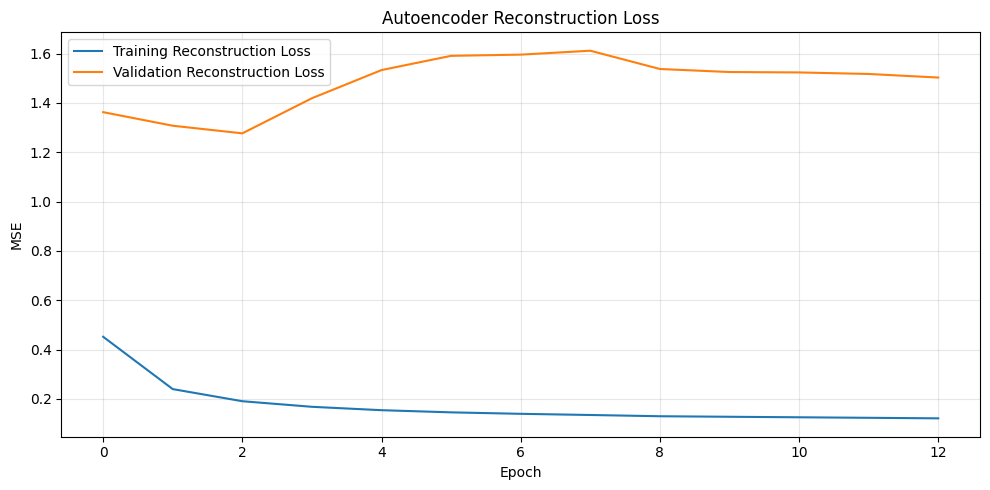

Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/results/figures/ae_reconstruction_loss.png


In [ ]:
plt.figure(
    figsize=(10, 5)
)

plt.plot(
    history_ae.history["loss"],
    label="Training Reconstruction Loss"
)

plt.plot(
    history_ae.history["val_loss"],
    label="Validation Reconstruction Loss"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "MSE"
)

plt.title(
    "Autoencoder Reconstruction Loss"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

ae_loss_path = os.path.join(
    FIGURES_DIR,
    "ae_reconstruction_loss.png"
)

plt.savefig(
    ae_loss_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    ae_loss_path
)

Evaluate AE reconstruction

In [ ]:
train_reconstruction = (
    autoencoder.predict(
        X_train_scaled,
        batch_size=256,
        verbose=0
    )
)

val_reconstruction = (
    autoencoder.predict(
        X_val_scaled,
        batch_size=256,
        verbose=0
    )
)

test_reconstruction = (
    autoencoder.predict(
        X_test_scaled,
        batch_size=256,
        verbose=0
    )
)

In [ ]:
train_reconstruction_mse = np.mean(
    (
        X_train_scaled -
        train_reconstruction
    ) ** 2
)

val_reconstruction_mse = np.mean(
    (
        X_val_scaled -
        val_reconstruction
    ) ** 2
)

test_reconstruction_mse = np.mean(
    (
        X_test_scaled -
        test_reconstruction
    ) ** 2
)

print("=" * 60)
print("AUTOENCODER RECONSTRUCTION RESULTS")
print("=" * 60)

print(
    "Train MSE      :",
    train_reconstruction_mse
)

print(
    "Validation MSE :",
    val_reconstruction_mse
)

print(
    "Test MSE       :",
    test_reconstruction_mse
)

AUTOENCODER RECONSTRUCTION RESULTS
Train MSE      : 0.17081305
Validation MSE : 1.2768546
Test MSE       : 1.2319435


Calculate reconstruction MAE

In [ ]:
train_reconstruction_mae = np.mean(
    np.abs(
        X_train_scaled -
        train_reconstruction
    )
)

val_reconstruction_mae = np.mean(
    np.abs(
        X_val_scaled -
        val_reconstruction
    )
)

test_reconstruction_mae = np.mean(
    np.abs(
        X_test_scaled -
        test_reconstruction
    )
)

print(
    "Train MAE      :",
    train_reconstruction_mae
)

print(
    "Validation MAE :",
    val_reconstruction_mae
)

print(
    "Test MAE       :",
    test_reconstruction_mae
)

Train MAE      : 0.23357339
Validation MAE : 0.7099598
Test MAE       : 0.69292504


Save AE reconstruction metrics

In [ ]:
ae_reconstruction_metrics = pd.DataFrame({

    "Dataset": [
        "Train",
        "Validation",
        "Test"
    ],

    "Reconstruction_MSE": [
        train_reconstruction_mse,
        val_reconstruction_mse,
        test_reconstruction_mse
    ],

    "Reconstruction_MAE": [
        train_reconstruction_mae,
        val_reconstruction_mae,
        test_reconstruction_mae
    ]
})

display(
    ae_reconstruction_metrics
)

,Dataset,Reconstruction_MSE,Reconstruction_MAE
0,Train,0.170813,0.233573
1,Validation,1.276855,0.709960
2,Test,1.231943,0.692925


In [ ]:
ae_metrics_path = os.path.join(
    METRICS_DIR,
    "ae_reconstruction_metrics.csv"
)

ae_reconstruction_metrics.to_csv(
    ae_metrics_path,
    index=False
)

print(
    "Metrics saved:",
    ae_metrics_path
)

Metrics saved: /content/drive/MyDrive/GC210_Retail_Forecasting/results/metrics/ae_reconstruction_metrics.csv


Extract latent features

In [ ]:
encoder = Model(
    inputs=input_layer,
    outputs=latent_layer,
    name="Encoder"
)

Z_train_ae = encoder.predict(
    X_train_scaled,
    batch_size=256,
    verbose=0
)

Z_val_ae = encoder.predict(
    X_val_scaled,
    batch_size=256,
    verbose=0
)

Z_test_ae = encoder.predict(
    X_test_scaled,
    batch_size=256,
    verbose=0
)

print("=" * 60)
print("AE LATENT FEATURES")
print("=" * 60)

print(
    "Original training:",
    X_train_scaled.shape
)

print(
    "AE latent training:",
    Z_train_ae.shape
)

print()

print(
    "Original validation:",
    X_val_scaled.shape
)

print(
    "AE latent validation:",
    Z_val_ae.shape
)

print()

print(
    "Original test:",
    X_test_scaled.shape
)

print(
    "AE latent test:",
    Z_test_ae.shape
)

AE LATENT FEATURES
Original training: (79200, 40)
AE latent training: (79200, 8)

Original validation: (300, 40)
AE latent validation: (300, 8)

Original test: (300, 40)
AE latent test: (300, 8)


Check latent features

In [ ]:
print(
    "Train latent finite:",
    np.isfinite(
        Z_train_ae
    ).all()
)

print(
    "Validation latent finite:",
    np.isfinite(
        Z_val_ae
    ).all()
)

print(
    "Test latent finite:",
    np.isfinite(
        Z_test_ae
    ).all()
)

print(
    "\nLatent mean:",
    np.mean(
        Z_train_ae
    )
)

print(
    "Latent std:",
    np.std(
        Z_train_ae
    )
)

Train latent finite: True
Validation latent finite: True
Test latent finite: True

Latent mean: -0.5719384
Latent std: 2.5073295


Create latent feature names

In [ ]:
AE_LATENT_FEATURES = [
    f"AE_Latent_{i}"
    for i in range(
        1,
        LATENT_DIM + 1
    )
]

print(
    AE_LATENT_FEATURES
)

['AE_Latent_1', 'AE_Latent_2', 'AE_Latent_3', 'AE_Latent_4', 'AE_Latent_5', 'AE_Latent_6', 'AE_Latent_7', 'AE_Latent_8']


Convert latent arrays into DataFrames

In [ ]:
train_latent_df = pd.DataFrame(
    Z_train_ae,
    columns=AE_LATENT_FEATURES
)

val_latent_df = pd.DataFrame(
    Z_val_ae,
    columns=AE_LATENT_FEATURES
)

test_latent_df = pd.DataFrame(
    Z_test_ae,
    columns=AE_LATENT_FEATURES
)

In [ ]:
ID_COLUMNS = []

for col in [
    "id",
    "series_key",
    "date"
]:

    if col in train_df.columns:
        ID_COLUMNS.append(col)

print(
    "Identification columns:",
    ID_COLUMNS
)

Identification columns: ['id', 'series_key', 'date']


In [ ]:
for col in ID_COLUMNS:

    train_latent_df[col] = (
        train_df[col]
        .reset_index(drop=True)
    )

    val_latent_df[col] = (
        val_df[col]
        .reset_index(drop=True)
    )

    test_latent_df[col] = (
        test_df[col]
        .reset_index(drop=True)
    )

In [ ]:
for target in TARGETS:

    train_latent_df[target] = (
        train_df[target]
        .reset_index(drop=True)
    )

    val_latent_df[target] = (
        val_df[target]
        .reset_index(drop=True)
    )

    test_latent_df[target] = (
        test_df[target]
        .reset_index(drop=True)
    )

Inspect latent dataset

In [ ]:
print(
    "Train latent dataset:",
    train_latent_df.shape
)

print(
    "Validation latent dataset:",
    val_latent_df.shape
)

print(
    "Test latent dataset:",
    test_latent_df.shape
)

display(
    train_latent_df.head()
)

Train latent dataset: (79200, 39)
Validation latent dataset: (300, 39)
Test latent dataset: (300, 39)


,AE_Latent_1,AE_Latent_2,AE_Latent_3,AE_Latent_4,AE_Latent_5,AE_Latent_6,AE_Latent_7,AE_Latent_8,id,series_key,...,target_day_19,target_day_20,target_day_21,target_day_22,target_day_23,target_day_24,target_day_25,target_day_26,target_day_27,target_day_28
0,-0.211154,2.912309,-2.790587,-0.353485,-0.471084,-2.838491,-1.671755,-2.767337,FOODS_1_005_TX_3_evaluation,FOODS_1_005_TX_3,...,1.0,2.0,1.0,2.0,1.0,0.0,0.0,3.0,2.0,1.0
1,-0.091717,3.069012,-2.801366,-0.366798,-0.775256,-2.529958,-1.832658,-2.274826,FOODS_1_005_TX_3_evaluation,FOODS_1_005_TX_3,...,3.0,2.0,1.0,0.0,2.0,2.0,0.0,1.0,0.0,0.0
2,-0.689404,2.796979,-2.627037,-0.104779,-0.379065,-3.474512,-1.927346,-2.741506,FOODS_1_005_TX_3_evaluation,FOODS_1_005_TX_3,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,2.0,0.0
3,-0.317513,3.202290,-2.232089,0.205529,-0.242744,-3.521189,-1.437061,-0.048529,FOODS_1_005_TX_3_evaluation,FOODS_1_005_TX_3,...,0.0,2.0,0.0,3.0,1.0,3.0,0.0,2.0,0.0,2.0
4,-0.096176,2.969817,-2.669845,0.176698,-0.449923,-3.126066,-1.436185,0.151233,FOODS_1_005_TX_3_evaluation,FOODS_1_005_TX_3,...,2.0,0.0,2.0,3.0,4.0,5.0,5.0,6.0,7.0,2.0


Save AE latent datasets

In [ ]:
AE_TRAIN_PATH = os.path.join(
    LATENT_DIR,
    "ae_train_latent.parquet"
)

AE_VAL_PATH = os.path.join(
    LATENT_DIR,
    "ae_validation_latent.parquet"
)

AE_TEST_PATH = os.path.join(
    LATENT_DIR,
    "ae_test_latent.parquet"
)

train_latent_df.to_parquet(
    AE_TRAIN_PATH,
    index=False
)

val_latent_df.to_parquet(
    AE_VAL_PATH,
    index=False
)

test_latent_df.to_parquet(
    AE_TEST_PATH,
    index=False
)

print("AE latent datasets saved.")

print(AE_TRAIN_PATH)
print(AE_VAL_PATH)
print(AE_TEST_PATH)

AE latent datasets saved.
/content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/latent_features/ae_train_latent.parquet
/content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/latent_features/ae_validation_latent.parquet
/content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/latent_features/ae_test_latent.parquet


Save Autoencoder and Encoder

In [ ]:
autoencoder_path = os.path.join(
    AE_MODEL_DIR,
    "autoencoder_final.keras"
)

autoencoder.save(
    autoencoder_path
)

print(
    "Autoencoder saved:",
    autoencoder_path
)

Autoencoder saved: /content/drive/MyDrive/GC210_Retail_Forecasting/models/autoencoder/autoencoder_final.keras


In [ ]:
encoder_path = os.path.join(
    AE_MODEL_DIR,
    "ae_encoder.keras"
)

encoder.save(
    encoder_path
)

print(
    "Encoder saved:",
    encoder_path
)

Encoder saved: /content/drive/MyDrive/GC210_Retail_Forecasting/models/autoencoder/ae_encoder.keras


Save AE configuration

In [ ]:
ae_config = {

    "model": "Autoencoder",

    "input_dimension":
        INPUT_DIM,

    "latent_dimension":
        LATENT_DIM,

    "encoder_architecture": [
        INPUT_DIM,
        32,
        16,
        LATENT_DIM
    ],

    "decoder_architecture": [
        LATENT_DIM,
        16,
        32,
        INPUT_DIM
    ],

    "loss":
        "mean_squared_error",

    "optimizer":
        "Adam",

    "learning_rate":
        0.001,

    "latent_features":
        AE_LATENT_FEATURES
}

AE_CONFIG_PATH = os.path.join(
    AE_MODEL_DIR,
    "ae_config.json"
)

with open(
    AE_CONFIG_PATH,
    "w"
) as f:

    json.dump(
        ae_config,
        f,
        indent=4
    )

print(
    "AE configuration saved."
)

AE configuration saved.


Visualize latent features with PCA

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(
    n_components=2,
    random_state=SEED
)

Z_train_pca = pca.fit_transform(
    Z_train_ae
)

print(
    "Explained variance:",
    pca.explained_variance_ratio_
)

print(
    "Total explained variance:",
    pca.explained_variance_ratio_.sum()
)

Explained variance: [0.43130916 0.25087175]
Total explained variance: 0.6821809


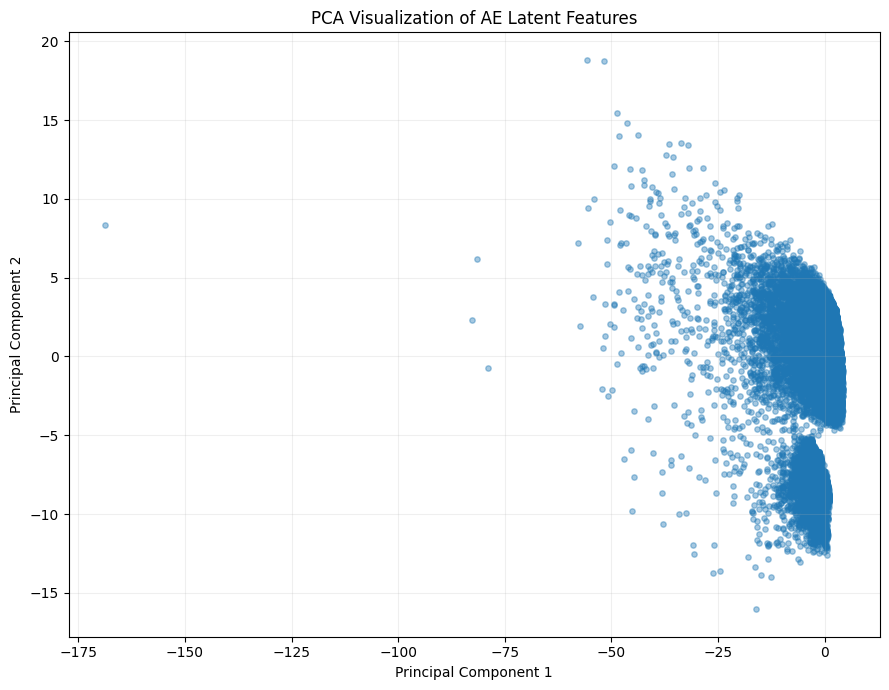

In [ ]:
plt.figure(
    figsize=(9, 7)
)

plt.scatter(
    Z_train_pca[:, 0],
    Z_train_pca[:, 1],
    alpha=0.4,
    s=15
)

plt.xlabel(
    "Principal Component 1"
)

plt.ylabel(
    "Principal Component 2"
)

plt.title(
    "PCA Visualization of AE Latent Features"
)

plt.grid(
    alpha=0.2
)

plt.tight_layout()

pca_path = os.path.join(
    FIGURES_DIR,
    "ae_latent_pca.png"
)

plt.savefig(
    pca_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Latent feature correlation analysis

In [ ]:
latent_only_df = pd.DataFrame(
    Z_train_ae,
    columns=AE_LATENT_FEATURES
)

latent_correlation = (
    latent_only_df.corr()
)

display(
    latent_correlation.round(3)
)

,AE_Latent_1,AE_Latent_2,AE_Latent_3,AE_Latent_4,AE_Latent_5,AE_Latent_6,AE_Latent_7,AE_Latent_8
AE_Latent_1,1.000,-0.529,-0.231,-0.178,-0.703,0.603,0.044,0.232
AE_Latent_2,-0.529,1.000,-0.099,-0.516,0.337,-0.604,-0.033,-0.124
AE_Latent_3,-0.231,-0.099,1.000,0.229,0.547,-0.293,0.256,-0.249
AE_Latent_4,-0.178,-0.516,0.229,1.000,0.118,0.187,-0.271,-0.100
AE_Latent_5,-0.703,0.337,0.547,0.118,1.000,-0.570,0.273,-0.075
AE_Latent_6,0.603,-0.604,-0.293,0.187,-0.570,1.000,-0.170,0.206
AE_Latent_7,0.044,-0.033,0.256,-0.271,0.273,-0.170,1.000,0.297
AE_Latent_8,0.232,-0.124,-0.249,-0.100,-0.075,0.206,0.297,1.000


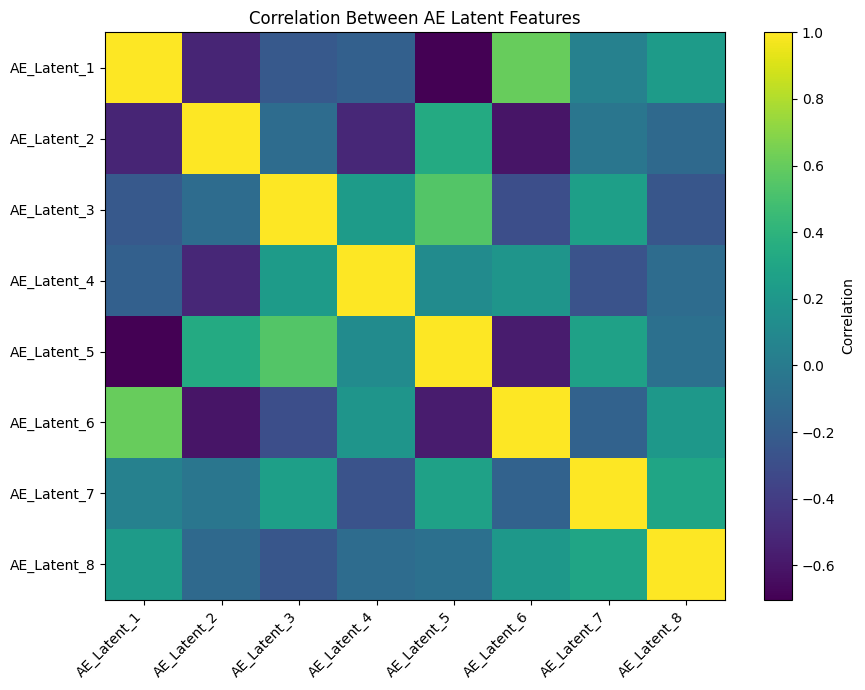

In [ ]:
plt.figure(
    figsize=(9, 7)
)

plt.imshow(
    latent_correlation,
    aspect="auto"
)

plt.colorbar(
    label="Correlation"
)

plt.xticks(
    range(LATENT_DIM),
    AE_LATENT_FEATURES,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(LATENT_DIM),
    AE_LATENT_FEATURES
)

plt.title(
    "Correlation Between AE Latent Features"
)

plt.tight_layout()

correlation_path = os.path.join(
    FIGURES_DIR,
    "ae_latent_correlation.png"
)

plt.savefig(
    correlation_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Latent feature correlation analysis

In [ ]:
latent_only_df = pd.DataFrame(
    Z_train_ae,
    columns=AE_LATENT_FEATURES
)

latent_correlation = (
    latent_only_df.corr()
)

display(
    latent_correlation.round(3)
)

,AE_Latent_1,AE_Latent_2,AE_Latent_3,AE_Latent_4,AE_Latent_5,AE_Latent_6,AE_Latent_7,AE_Latent_8
AE_Latent_1,1.000,-0.529,-0.231,-0.178,-0.703,0.603,0.044,0.232
AE_Latent_2,-0.529,1.000,-0.099,-0.516,0.337,-0.604,-0.033,-0.124
AE_Latent_3,-0.231,-0.099,1.000,0.229,0.547,-0.293,0.256,-0.249
AE_Latent_4,-0.178,-0.516,0.229,1.000,0.118,0.187,-0.271,-0.100
AE_Latent_5,-0.703,0.337,0.547,0.118,1.000,-0.570,0.273,-0.075
AE_Latent_6,0.603,-0.604,-0.293,0.187,-0.570,1.000,-0.170,0.206
AE_Latent_7,0.044,-0.033,0.256,-0.271,0.273,-0.170,1.000,0.297
AE_Latent_8,0.232,-0.124,-0.249,-0.100,-0.075,0.206,0.297,1.000


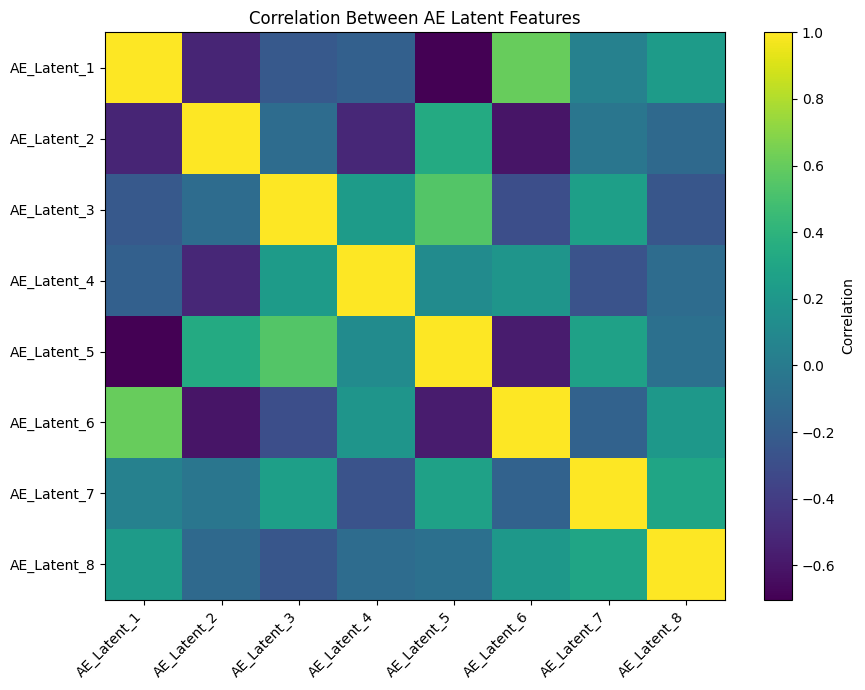

In [ ]:
plt.figure(
    figsize=(9, 7)
)

plt.imshow(
    latent_correlation,
    aspect="auto"
)

plt.colorbar(
    label="Correlation"
)

plt.xticks(
    range(LATENT_DIM),
    AE_LATENT_FEATURES,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(LATENT_DIM),
    AE_LATENT_FEATURES
)

plt.title(
    "Correlation Between AE Latent Features"
)

plt.tight_layout()

correlation_path = os.path.join(
    FIGURES_DIR,
    "ae_latent_correlation.png"
)

plt.savefig(
    correlation_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Important forecasting experiment: AE + MLP

In [ ]:
y_train = train_df[
    TARGETS
].to_numpy(
    dtype=np.float32
)

y_val = val_df[
    TARGETS
].to_numpy(
    dtype=np.float32
)

y_test = test_df[
    TARGETS
].to_numpy(
    dtype=np.float32
)

print(
    y_train.shape,
    y_val.shape,
    y_test.shape
)

(79200, 28) (300, 28) (300, 28)


Build AE + MLP forecasting model

In [ ]:
tf.keras.backend.clear_session()

ae_mlp_model = tf.keras.Sequential([

    Input(
        shape=(LATENT_DIM,)
    ),

    Dense(
        64,
        activation="relu"
    ),

    BatchNormalization(),

    Dropout(
        0.20
    ),

    Dense(
        32,
        activation="relu"
    ),

    Dropout(
        0.10
    ),

    Dense(
        HORIZON,
        activation="linear"
    )
])

ae_mlp_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 28)             │           924 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,836 (14.98 KB)

 Trainable params: 3,708 (14.48 KB)

 Non-trainable params: 128 (512.00 B)

Compile AE + MLP

In [ ]:
ae_mlp_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="mae",

    metrics=[
        tf.keras.metrics.MeanAbsoluteError(
            name="mae"
        )
    ]
)

In [ ]:
ae_mlp_early_stop = EarlyStopping(

    monitor="val_loss",

    patience=8,

    restore_best_weights=True,

    verbose=1
)

ae_mlp_reduce_lr = ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.5,

    patience=4,

    min_lr=1e-6,

    verbose=1
)

Train AE + MLP

In [ ]:
history_ae_mlp = ae_mlp_model.fit(

    Z_train_ae,
    y_train,

    validation_data=(
        Z_val_ae,
        y_val
    ),

    epochs=60,

    batch_size=256,

    callbacks=[
        ae_mlp_early_stop,
        ae_mlp_reduce_lr
    ],

    verbose=1
)

Epoch 1/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.8001 - mae: 0.8001 - val_loss: 0.8764 - val_mae: 0.8764 - learning_rate: 0.0010
Epoch 2/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.7105 - mae: 0.7105 - val_loss: 0.8733 - val_mae: 0.8733 - learning_rate: 0.0010
Epoch 3/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.7035 - mae: 0.7035 - val_loss: 0.9052 - val_mae: 0.9052 - learning_rate: 0.0010
Epoch 4/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.7002 - mae: 0.7002 - val_loss: 0.9214 - val_mae: 0.9214 - learning_rate: 0.0010
Epoch 5/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.6989 - mae: 0.6989 - val_loss: 0.9753 - val_mae: 0.9753 - learning_rate: 0.0010
Epoch 6/60
306/310 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.6936 - mae: 0.6936
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
310/310 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.6970 - mae: 0.6970 - val_loss: 0.9440 - val_mae: 0.9440 - learning_rate: 0.0010
Ep

Generate AE + MLP forecasts

In [ ]:
val_pred_ae_mlp = (
    ae_mlp_model.predict(
        Z_val_ae,
        batch_size=256,
        verbose=0
    )
)

test_pred_ae_mlp = (
    ae_mlp_model.predict(
        Z_test_ae,
        batch_size=256,
        verbose=0
    )
)

val_pred_ae_mlp = np.clip(
    val_pred_ae_mlp,
    0,
    None
)

test_pred_ae_mlp = np.clip(
    test_pred_ae_mlp,
    0,
    None
)

print(
    "Validation:",
    val_pred_ae_mlp.shape
)

print(
    "Test:",
    test_pred_ae_mlp.shape
)

Validation: (300, 28)
Test: (300, 28)


Evaluation function

In [ ]:
def calculate_forecast_metrics(
    y_true,
    y_pred
):

    y_true = np.asarray(
        y_true,
        dtype=np.float64
    )

    y_pred = np.asarray(
        y_pred,
        dtype=np.float64
    )

    y_pred = np.clip(
        y_pred,
        0,
        None
    )

    mae = np.mean(
        np.abs(
            y_true - y_pred
        )
    )

    rmse = np.sqrt(
        np.mean(
            (y_true - y_pred) ** 2
        )
    )

    denominator = np.sum(
        np.abs(y_true)
    )

    wape = (
        np.sum(
            np.abs(
                y_true - y_pred
            )
        )
        /
        denominator
        * 100
        if denominator > 0
        else np.nan
    )

    smape_denominator = (
        np.abs(y_true)
        +
        np.abs(y_pred)
    )

    smape_values = np.divide(

        2 * np.abs(
            y_true - y_pred
        ),

        smape_denominator,

        out=np.zeros_like(
            y_true,
            dtype=np.float64
        ),

        where=(
            smape_denominator != 0
        )
    )

    smape = (
        np.mean(
            smape_values
        ) * 100
    )

    return {
        "MAE": float(mae),
        "RMSE": float(rmse),
        "WAPE": float(wape),
        "sMAPE": float(smape)
    }

Evaluate AE + MLP

In [ ]:
ae_mlp_val_metrics = (
    calculate_forecast_metrics(
        y_val,
        val_pred_ae_mlp
    )
)

ae_mlp_test_metrics = (
    calculate_forecast_metrics(
        y_test,
        test_pred_ae_mlp
    )
)

print("=" * 60)
print("AE + MLP RESULTS")
print("=" * 60)

print("\nVALIDATION")

for metric, value in (
    ae_mlp_val_metrics.items()
):

    print(
        f"{metric}: {value:.4f}"
    )

print("\nTEST")

for metric, value in (
    ae_mlp_test_metrics.items()
):

    print(
        f"{metric}: {value:.4f}"
    )

AE + MLP RESULTS

VALIDATION
MAE: 0.8729
RMSE: 1.6814
WAPE: 74.0998
sMAPE: 140.8287

TEST
MAE: 1.0662
RMSE: 1.8089
WAPE: 89.8639
sMAPE: 136.1644


Compare MLP vs AE + MLP

In [ ]:
baseline_metrics_path = os.path.join(
    METRICS_DIR,
    "baseline_test_metrics.csv"
)

baseline_results = pd.read_csv(
    baseline_metrics_path
)

display(
    baseline_results
)

,Model,MAE,RMSE,WAPE,sMAPE
0,Seasonal Naive,1.255476,2.874394,105.819787,86.528972
1,MLP,0.900348,1.843470,75.887268,151.595465
2,LightGBM,0.846885,1.805397,71.381020,102.498205


In [ ]:
ae_mlp_result = pd.DataFrame([{

    "Model":
        "AE + MLP",

    "MAE":
        ae_mlp_test_metrics["MAE"],

    "RMSE":
        ae_mlp_test_metrics["RMSE"],

    "WAPE":
        ae_mlp_test_metrics["WAPE"],

    "sMAPE":
        ae_mlp_test_metrics["sMAPE"]
}])

In [ ]:
step7_comparison = pd.concat(
    [
        baseline_results,
        ae_mlp_result
    ],
    ignore_index=True
)

display(
    step7_comparison.round(4)
)

,Model,MAE,RMSE,WAPE,sMAPE
0,Seasonal Naive,1.2555,2.8744,105.8198,86.5290
1,MLP,0.9003,1.8435,75.8873,151.5955
2,LightGBM,0.8469,1.8054,71.3810,102.4982
3,AE + MLP,1.0662,1.8089,89.8639,136.1644


Save AE + MLP results

In [ ]:
step7_results_path = os.path.join(
    METRICS_DIR,
    "ae_mlp_comparison.csv"
)

step7_comparison.to_csv(
    step7_results_path,
    index=False
)

print(
    "Saved:",
    step7_results_path
)

Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/results/metrics/ae_mlp_comparison.csv


Save AE + MLP model

In [ ]:
ae_mlp_model_path = os.path.join(
    AE_MODEL_DIR,
    "ae_mlp_forecaster.keras"
)

ae_mlp_model.save(
    ae_mlp_model_path
)

print(
    "Saved:",
    ae_mlp_model_path
)

Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/models/autoencoder/ae_mlp_forecaster.keras


Save AE + MLP predictions

In [ ]:
prediction_rows = []

if "series_key" in test_df.columns:

    test_ids = (
        test_df["series_key"]
        .astype(str)
        .values
    )

else:

    test_ids = (
        test_df["id"]
        .astype(str)
        .values
    )


for i in range(
    len(test_df)
):

    for h in range(
        HORIZON
    ):

        prediction_rows.append({

            "series_id":
                test_ids[i],

            "forecast_day":
                h + 1,

            "actual":
                float(
                    y_test[i, h]
                ),

            "prediction":
                float(
                    test_pred_ae_mlp[i, h]
                ),

            "model":
                "AE + MLP"
        })


ae_mlp_predictions = pd.DataFrame(
    prediction_rows
)

In [ ]:
AE_PREDICTION_PATH = os.path.join(
    RESULTS_DIR,
    "predictions",
    "ae_mlp_test_predictions.csv"
)

ae_mlp_predictions.to_csv(
    AE_PREDICTION_PATH,
    index=False
)

print(
    "Predictions saved:",
    AE_PREDICTION_PATH
)

Predictions saved: /content/drive/MyDrive/GC210_Retail_Forecasting/results/predictions/ae_mlp_test_predictions.csv


Plot AE + MLP training

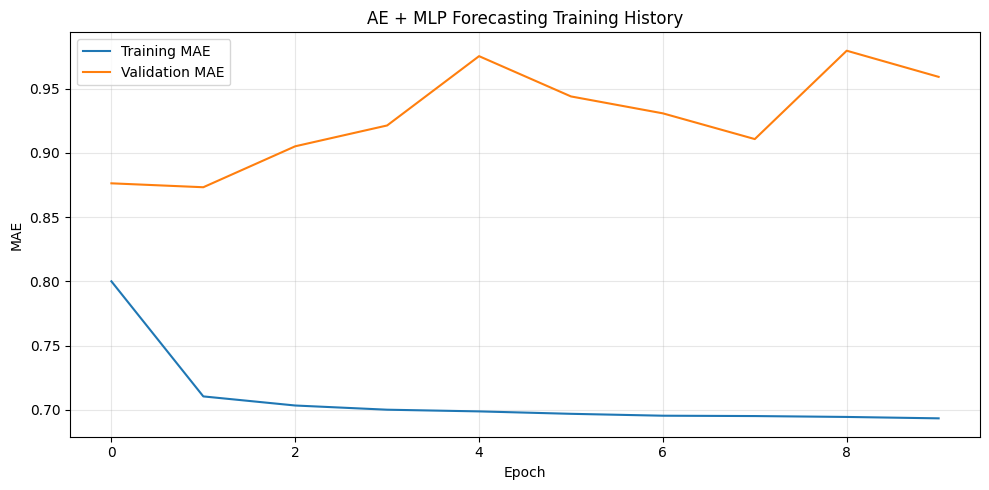

In [ ]:
plt.figure(
    figsize=(10, 5)
)

plt.plot(
    history_ae_mlp.history["loss"],
    label="Training MAE"
)

plt.plot(
    history_ae_mlp.history["val_loss"],
    label="Validation MAE"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "MAE"
)

plt.title(
    "AE + MLP Forecasting Training History"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

ae_mlp_history_path = os.path.join(
    FIGURES_DIR,
    "ae_mlp_training_history.png"
)

plt.savefig(
    ae_mlp_history_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

AE + MLP horizon analysis

In [ ]:
ae_mlp_horizon_mae = np.mean(
    np.abs(
        y_test -
        test_pred_ae_mlp
    ),
    axis=0
)

ae_horizon_df = pd.DataFrame({

    "Forecast_Day":
        np.arange(
            1,
            HORIZON + 1
        ),

    "AE_MLP_MAE":
        ae_mlp_horizon_mae
})

display(
    ae_horizon_df
)

,Forecast_Day,AE_MLP_MAE
0,1,0.928664
1,2,1.007276
2,3,1.100092
3,4,1.264158
4,5,1.157635
5,6,1.083139
6,7,1.052521
7,8,0.849700
8,9,0.937064
9,10,1.068052


In [ ]:
ae_horizon_df.to_csv(
    os.path.join(
        METRICS_DIR,
        "ae_mlp_horizon_mae.csv"
    ),
    index=False
)

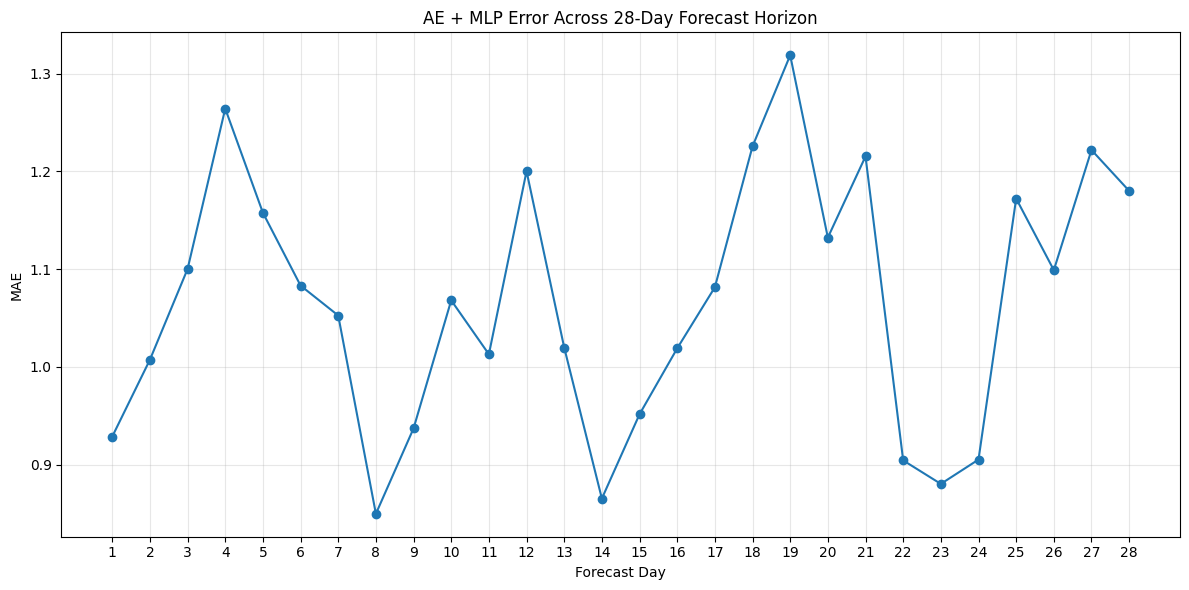

In [ ]:
plt.figure(
    figsize=(12, 6)
)

plt.plot(
    np.arange(
        1,
        HORIZON + 1
    ),
    ae_mlp_horizon_mae,
    marker="o"
)

plt.xlabel(
    "Forecast Day"
)

plt.ylabel(
    "MAE"
)

plt.title(
    "AE + MLP Error Across 28-Day Forecast Horizon"
)

plt.xticks(
    np.arange(
        1,
        29
    )
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURES_DIR,
        "ae_mlp_horizon_mae.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Final verification

In [ ]:
print("=" * 75)
print("STEP 7 - AUTOENCODER FINAL VERIFICATION")
print("=" * 75)

print("\n1. ORIGINAL FEATURES")
print("-" * 40)

print(
    "Input features:",
    len(FEATURES)
)

print(
    "Train:",
    X_train_scaled.shape
)

print(
    "Validation:",
    X_val_scaled.shape
)

print(
    "Test:",
    X_test_scaled.shape
)


print("\n2. AUTOENCODER")
print("-" * 40)

print(
    "Input dimension:",
    INPUT_DIM
)

print(
    "Latent dimension:",
    LATENT_DIM
)

print(
    "Train reconstruction MSE:",
    round(
        float(
            train_reconstruction_mse
        ),
        6
    )
)

print(
    "Validation reconstruction MSE:",
    round(
        float(
            val_reconstruction_mse
        ),
        6
    )
)

print(
    "Test reconstruction MSE:",
    round(
        float(
            test_reconstruction_mse
        ),
        6
    )
)


print("\n3. LATENT FEATURES")
print("-" * 40)

print(
    "AE train:",
    Z_train_ae.shape
)

print(
    "AE validation:",
    Z_val_ae.shape
)

print(
    "AE test:",
    Z_test_ae.shape
)


print("\n4. FORECASTING")
print("-" * 40)

print(
    "AE+MLP validation:",
    val_pred_ae_mlp.shape
)

print(
    "AE+MLP test:",
    test_pred_ae_mlp.shape
)


print("\n5. AE + MLP TEST METRICS")
print("-" * 40)

for metric, value in (
    ae_mlp_test_metrics.items()
):

    print(
        f"{metric:8s}: "
        f"{value:.4f}"
    )


print("\n6. SAVED FILES")
print("-" * 40)

files_to_verify = {

    "Autoencoder":
        autoencoder_path,

    "Encoder":
        encoder_path,

    "AE+MLP":
        ae_mlp_model_path,

    "AE Train Latent":
        AE_TRAIN_PATH,

    "AE Validation Latent":
        AE_VAL_PATH,

    "AE Test Latent":
        AE_TEST_PATH,

    "AE Configuration":
        AE_CONFIG_PATH,

    "AE Predictions":
        AE_PREDICTION_PATH
}

all_saved = True

for name, path in (
    files_to_verify.items()
):

    exists = os.path.exists(
        path
    )

    print(
        f"{name:25s}:",
        "FOUND"
        if exists
        else "MISSING"
    )

    if not exists:
        all_saved = False


print("\n" + "=" * 75)

if all_saved:

    print(
        "STEP 7 COMPLETED SUCCESSFULLY"
    )

    print(
        "41 FEATURES -> AE -> "
        "8 LATENT FEATURES -> "
        "MLP -> 28-DAY FORECAST"
    )

else:

    print(
        "STEP 7 INCOMPLETE - "
        "CHECK MISSING FILES ABOVE"
    )

print("=" * 75)

STEP 7 - AUTOENCODER FINAL VERIFICATION

1. ORIGINAL FEATURES
----------------------------------------
Input features: 40
Train: (79200, 40)
Validation: (300, 40)
Test: (300, 40)

2. AUTOENCODER
----------------------------------------
Input dimension: 40
Latent dimension: 8
Train reconstruction MSE: 0.170813
Validation reconstruction MSE: 1.276855
Test reconstruction MSE: 1.231943

3. LATENT FEATURES
----------------------------------------
AE train: (79200, 8)
AE validation: (300, 8)
AE test: (300, 8)

4. FORECASTING
----------------------------------------
AE+MLP validation: (300, 28)
AE+MLP test: (300, 28)

5. AE + MLP TEST METRICS
----------------------------------------
MAE     : 1.0662
RMSE    : 1.8089
WAPE    : 89.8639
sMAPE   : 136.1644

6. SAVED FILES
----------------------------------------
Autoencoder              : FOUND
Encoder                  : FOUND
AE+MLP                   : FOUND
AE Train Latent          : FOUND
AE Validation Latent     : FOUND
AE Test Latent        